In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import reliability_utils as ru
import infrastructure_utils as iu
import matplotlib as mpl

### EICV reliability

In [2]:
### Clean data
# Demographics -------
# import household file in python
dir_path = '/home/qsel/Desktop/data/REG_electricity_expenditure/eicv5/'
# dir_path = '/Users/joelmugyenyi/Google Drive/My Drive/rwanda_drive/elec_consumption/data/eicv5/'

eicv_reliability = pd.read_spss(dir_path+'cs_S0_S5_Household.sav') 
eicv_reliability=eicv_reliability[['hhid','s5cq16a5','s5cq16a6','s5cq16a8',
's5cq16a9','s5cq16a10','s5cq16a11']].rename(columns={
    's5cq16a5':'eicv_overall_electricity_availability',
    's5cq16a6':'eicv_evening_electricity_availability',
    # 's5cq16a7':'incorrect_evening_availabilty',
    's5cq16a8':'eicv_outage_frequency',
    's5cq16a9':'eicv_outage_duration',
    's5cq16a10':'eicv_damaged_appliances',
    's5cq16a11':'eicv_death_due_electricity',
})
eicv_reliability['eicv_evening_electricity_availability'] = eicv_reliability['eicv_evening_electricity_availability'].replace({
    '4 hours':4,
    '3 hours':3,
    '2 hours':2,
    '1 Hour':1
    })

# eicv_reliability=eicv_reliability.merge(electricity[[
# 'hhid','no_electricity','grid','solar','generator','solar','lantern','battery','other']],how='left')
eicv_reliability['eicv_damaged_appliances']=eicv_reliability['eicv_damaged_appliances'].replace({
    'Yes':1,'No':0}).fillna(0)
eicv_reliability['eicv_death_due_electricity']=eicv_reliability['eicv_death_due_electricity'].replace({
    'Yes':1,'No':0}).fillna(0)
eicv_reliability['eicv_overall_electricity_availability_dont_know']=eicv_reliability.eicv_overall_electricity_availability.apply(
    lambda x: 0 if x!="Don't know" else 1).fillna(0)

eicv_reliability['eicv_evening_electricity_availability_dont_know']=eicv_reliability.eicv_evening_electricity_availability.apply(
    lambda x: 0 if x!="Don't know" else 1).fillna(0)

eicv_reliability['eicv_outage_frequency_dont_know']=eicv_reliability.eicv_outage_frequency.apply(
    lambda x: 0 if x!="Don't know" else 1).fillna(0)

eicv_reliability['eicv_outage_duration_dont_know']=eicv_reliability.eicv_outage_duration.apply(
    lambda x: 0 if x!="Don't know" else 1).fillna(0)

eicv_reliability['eicv_evening_electricity_availability'] = pd.to_numeric(
    eicv_reliability['eicv_evening_electricity_availability'], errors='ignore')
eicv_reliability['eicv_overall_electricity_availability'] = pd.to_numeric(
    eicv_reliability['eicv_overall_electricity_availability'], errors='ignore')
eicv_reliability.eicv_outage_frequency = pd.to_numeric(eicv_reliability.eicv_outage_frequency, errors='coerce')
eicv_reliability.eicv_outage_duration  = pd.to_numeric(eicv_reliability.eicv_outage_duration, errors='coerce')/60

# keep relevant columns
eicv_reliability = eicv_reliability[['hhid','eicv_overall_electricity_availability','eicv_evening_electricity_availability',
'eicv_outage_frequency','eicv_outage_duration','eicv_damaged_appliances','eicv_death_due_electricity']]
eicv_reliability = eicv_reliability.replace("Don't know",np.nan) # replace all "dont know" with NaN

/home/qsel/miniconda3/envs/geo_env/lib/python3.11/site-packages/pandas/io/spss.py:66: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df, metadata = pyreadstat.read_sav(
/home/qsel/miniconda3/envs/geo_env/lib/python3.11/site-packages/pandas/io

In [3]:
metric = 'frequency'
# metric = 'duration'
if metric == 'frequency':
    data = eicv_reliability.eicv_outage_frequency
elif metric == 'duration':
    data = eicv_reliability.eicv_outage_duration
else:
    raise Exception('Wrong input')
print(f'mean reported outage  {metric}: {round(data.mean(),2)}')
print(f'std reported outage  {metric}: {round(data.std(),2)}')
print(f'min reported outage  {metric}: {round(data.min(),2)}')
print(f'max reported outage  {metric}: {round(data.max(),2)}')


mean reported outage  frequency: 0.7
std reported outage  frequency: 1.01
min reported outage  frequency: 0.0
max reported outage  frequency: 8.0


### Actual reliability

In [4]:
%%time
# Define Projection 
project_crs = 'epsg:32735'
geo_crs = 'epsg:4326'

# district shapefile
# dir_path = '/home/qsel/Desktop/data/consumption_data/'
dir_path = '../data/raw/'
districts = gpd.read_file(dir_path+'District_Boundaries.geojson').to_crs('epsg:32735')
districts['district'] = districts['district'].str.lower() # convert to lower


# lines
# dir_path = '~/Desktop/data/REG_Tariffs/LV_lines/'
dir_path = '../data/raw/LV_lines/'
lines = gpd.read_file(dir_path+'lv_lines.shp')


# Reliability data
mv_outages_2020 = pd.read_excel('../data/raw/reg_reliability/MV_Outages_2020.xlsx',
                                sheet_name='Detailed',header=3)
mv_outages_2019 = pd.read_excel('../data/raw/reg_reliability/MV_Outages_2016-2019.xlsx',
                                sheet_name='2019',header=2)
mv_outages_2018 = pd.read_excel('../data/raw/reg_reliability/MV_Outages_2016-2019.xlsx',
                                sheet_name='2018',header=1)
mv_outages_2017 = pd.read_excel('../data/raw/reg_reliability/MV_Outages_2016-2019.xlsx',
                                sheet_name='2017',header=2)
mv_outages_2016 = pd.read_excel('../data/raw/reg_reliability/MV_Outages_2016-2019.xlsx',
                                sheet_name='2016',header=1)
mv_outages_2016['Time(h)']=pd.to_timedelta(mv_outages_2016['Duration'].astype(str),
                                           errors='coerce').dt.total_seconds()/3600

/home/qsel/miniconda3/envs/geo_env/lib/python3.11/site-packages/geopandas/io/file.py:364: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  as_dt = pd.to_datetime(df[k], errors="ignore")
/home/qsel/miniconda3/envs/geo_env/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)
/home/qsel/miniconda3/envs/geo_env/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


CPU times: user 26.7 s, sys: 252 ms, total: 27 s
Wall time: 1min 16s


### Number of feeders across time

In [6]:
num_of_feeders_2016 = mv_outages_2016.Feeder.str.strip().str.lower().nunique()
num_of_feeders_2017 = mv_outages_2017.Feeder.str.strip().str.lower().nunique()
num_of_feeders_2018 = mv_outages_2018.Feeder.str.strip().str.lower().nunique()
num_of_feeders_2019 = mv_outages_2019.Feeder.str.strip().str.lower().nunique()
num_of_feeders_2020 = mv_outages_2020.Feeder.str.strip().str.lower().nunique()
number_of_feeders = {2016:num_of_feeders_2016,2017:num_of_feeders_2017,2018:num_of_feeders_2018,2019:num_of_feeders_2019,2020:num_of_feeders_2020}

for key,value in number_of_feeders.items():
    print(f'The number of feeders in {key} was {value}')

The number of feeders in 2016 was 53
The number of feeders in 2017 was 63
The number of feeders in 2018 was 73
The number of feeders in 2019 was 92
The number of feeders in 2020 was 77


In [8]:

# clean_meta_df = ru.clean_meta_data(meta_df)
# clean dataframes
reliablity_dfs = ru.clean_reliability_files(mv_outages_2020, mv_outages_2019, mv_outages_2018,
                                             mv_outages_2017, mv_outages_2016) # remove whitespace and convert to lowercase
cleaned_lines, feeder_bboxs_gdf =  ru.clean_lines(lines)
cleaned_lines = cleaned_lines.to_crs(project_crs) # convert to projection crs

# replace feedernames using 'lines' dataset feedernames as the true names
# cleaned_lines['Feeder_Nam'] = cleaned_lines['Feeder_Nam'].replace(ru.mapping_dict_lines)
reliablity_dfs[4]['Feeder'] = reliablity_dfs[4]['Feeder'].replace(ru.mapping_dict_2016)
reliablity_dfs[3]['Feeder'] = reliablity_dfs[3]['Feeder'].replace(ru.mapping_dict_2017)
reliablity_dfs[2]['Feeder'] = reliablity_dfs[2]['Feeder'].replace(ru.mapping_dict_2018)
reliablity_dfs[1]['Feeder'] = reliablity_dfs[1]['Feeder'].replace(ru.mapping_dict_2019)
reliablity_dfs[0]['Feeder'] = reliablity_dfs[0]['Feeder'].replace(ru.mapping_dict_2020)



# Groupby feeder names and compute outage_freq and outage_duration stats
feeder_reliability_2016 = reliablity_dfs[4].groupby(['Feeder',])['Time(h)'].agg(outage_freq_2016='count',
                                                                  outage_duration_2016='sum').reset_index().rename(
    columns={'Feeder':'Feeder_Nam'})
feeder_reliability_2017 = reliablity_dfs[3].groupby(['Feeder',])['Time(h)'].agg(outage_freq_2017='count',
                                                                  outage_duration_2017='sum').reset_index().rename(
    columns={'Feeder':'Feeder_Nam'})
feeder_reliability_2018 = reliablity_dfs[2].groupby(['Feeder',])['Time(h)'].agg(outage_freq_2018='count',
                                                                  outage_duration_2018='sum').reset_index().rename(
    columns={'Feeder':'Feeder_Nam'})
feeder_reliability_2019 = reliablity_dfs[1].groupby(['Feeder',])['Time(h)'].agg(outage_freq_2019='count',
                                                                  outage_duration_2019='sum').reset_index().rename(
    columns={'Feeder':'Feeder_Nam'})
feeder_reliability_2020 = reliablity_dfs[0].groupby(['Feeder',])['Time(h)'].agg(outage_freq_2020='count',
                                                                  outage_duration_2020='sum').reset_index().rename(
    columns={'Feeder':'Feeder_Nam'})


# Merge dataframes
        # merge reliability dara across all years
merged_feeder_reliability = pd.merge(feeder_reliability_2016,feeder_reliability_2017,how='outer')
merged_feeder_reliability = pd.merge(merged_feeder_reliability,feeder_reliability_2018,how='outer')
merged_feeder_reliability = pd.merge(merged_feeder_reliability,feeder_reliability_2019,how='outer')
merged_feeder_reliability = pd.merge(merged_feeder_reliability,feeder_reliability_2020,how='outer')

    # compute means across all years
duration_cols = ['outage_duration_2016','outage_duration_2017','outage_duration_2018','outage_duration_2019','outage_duration_2020',]
frequency_cols = ['outage_freq_2016', 'outage_freq_2017','outage_freq_2018','outage_freq_2019','outage_freq_2020']
merged_feeder_reliability['mean_frequency'] = merged_feeder_reliability[frequency_cols].mean(axis=1)
merged_feeder_reliability['mean_outage_duration'] = merged_feeder_reliability[duration_cols].mean(axis=1)


    # merge with line gps
lines_reliabilty = cleaned_lines.merge(feeder_reliability_2016,how='left',on='Feeder_Nam')
lines_reliabilty = lines_reliabilty.merge(feeder_reliability_2017,how='left',on='Feeder_Nam')
lines_reliabilty = lines_reliabilty.merge(feeder_reliability_2018,how='left',on='Feeder_Nam')
lines_reliabilty = lines_reliabilty.merge(feeder_reliability_2019,how='left',on='Feeder_Nam')
lines_reliabilty = lines_reliabilty.merge(feeder_reliability_2020,how='left',on='Feeder_Nam')
lines_reliabilty=lines_reliabilty[~((lines_reliabilty.outage_freq_2016.isna())&(lines_reliabilty.outage_freq_2017.isna())&(lines_reliabilty.outage_freq_2018.isna())
                                    &(lines_reliabilty.outage_freq_2019.isna())&(lines_reliabilty.outage_freq_2020.isna()))] # remove Nones



In [10]:
cleaned_lines

,OBJECTID,Substation,Feeder_Nam,Transforme,Voltage,Conductor_,Conductor1,Phases,Type_,Length,Year_of_Co,Notes,created_us,created_da,last_edite,last_edi_1,Branch_Nam,geometry
0,55376,kilinda,birambo,None,230.0,2*35mm2,Al twisted,Single Phase,Overhead,1.183172,0.0,None,SDE,2020-10-08,SDE,2021-06-02,rutsiro,"LINESTRING (779439.152 9772348.843, 779440.785..."
1,55377,kilinda,birambo,None,230.0,2*35mm2,Al twisted,Single Phase,Overhead,0.067960,0.0,None,SDE,2020-10-08,SDE,2021-06-02,rutsiro,"LINESTRING (780215.884 9772430.173, 780247.314..."
4688,65724,kilinda,birambo,None,230.0,2*35mm2,Al twisted,Single Phase,Overhead,0.474975,0.0,None,SDE,2020-10-08,SDE,2021-06-02,ngororero,"LINESTRING (788457.165 9771906.210, 788458.527..."
4689,65725,kilinda,birambo,None,230.0,2*35mm2,Al twisted,Single Phase,Overhead,0.613447,0.0,None,SDE,2020-10-08,SDE,2021-06-02,ngororero,"LINESTRING (788458.527 9771899.385, 788414.287..."
4690,65726,kilinda,birambo,None,230.0,2*35mm2,Al twisted,Single Phase,Overhead,0.177636,0.0,None,SDE,2020-10-08,SDE,2021-06-02,ngororero,"LINESTRING (786409.865 9772310.966, 786403.894..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51756,130247,camp belge,kinigi,GASIZA,420.0,2*25mm2,Al twisted,Single Phase,Overhead,0.285365,0.0,None,SDE,2022-02-07,SDE,2022-02-07,musanze,"LINESTRING (795088.258 9839428.997, 795128.193..."
51840,130331,camp belge,kinigi,GORILLA NEST,400.0,2*16mm2,Al twisted,Single Phase,Overhead,0.191030,0.0,None,SDE,2022-02-07,SDE,2022-02-07,musanze,"LINESTRING (787340.090 9840743.402, 787385.256..."
51841,130332,camp belge,kinigi,GORILLA NEST,400.0,2*16mm2,Al twisted,Single Phase,Overhead,0.111379,0.0,None,SDE,2022-02-07,SDE,2022-02-07,musanze,"LINESTRING (787501.893 9840841.511, 787512.459..."
51842,130333,camp belge,kinigi,GORILLA NEST,400.0,2*25mm2,Al twisted,Single Phase,Overhead,0.102502,0.0,None,SDE,2022-02-07,SDE,2022-02-07,musanze,"LINESTRING (787607.726 9840876.381, 787658.774..."


### Closest line way

In [12]:
electricity = pd.read_csv('../data/processed/electricity.csv')
electricity = electricity.drop(columns=['cluster', 'province', 'district'])
electricity_hhs = electricity[electricity.grid==1].hhid.tolist()

# eicv_file = '/home/qsel/Desktop/data/REG_electricity_expenditure/EICV5_Person_Household_Shared_13_02_2023v.csv'
eicv_file = '../data/eicv5/EICV5_Person_Household_Shared_13_02_2023v.csv'
eicv_HH = pd.read_csv(eicv_file, encoding='latin-1', low_memory=False)
survey = iu.get_survey_geopandas_df(eicv_HH, geo_crs='epsg:4326', project_crs='epsg:32735', project=True)
survey_ongrid = survey[survey.hhid.isin(electricity_hhs)] # select HHs that are on the grid
# merge HHs to nearest feeder lines and must be within a maximum distance of 600 meters
max_grid_distance = 600
survey_ongrid_reliability = survey_ongrid.sjoin_nearest(lines_reliabilty[['geometry','outage_duration_2016','outage_duration_2017','outage_duration_2018','outage_duration_2019','outage_duration_2020',
                                                                          'outage_freq_2016','outage_freq_2017','outage_freq_2018','outage_freq_2019','outage_freq_2020','Substation','Feeder_Nam']]
                                                                          ,max_distance=max_grid_distance,distance_col='dist').drop('index_right',axis=1).drop_duplicates(keep='last')
survey_ongrid_reliability = survey_ongrid_reliability[['hhid','outage_duration_2016','outage_duration_2017','outage_duration_2018','outage_duration_2019','outage_duration_2020',
                                                       'outage_freq_2016','outage_freq_2017','outage_freq_2018','outage_freq_2019','outage_freq_2020','district','Feeder_Nam']].merge(survey[['hhid','district']],how='right')
            # uncomment this line to include survey reported reliability measures
# survey_ongrid_reliability=survey_ongrid_reliability.merge(eicv_reliability).drop('district',axis=1)
survey_ongrid_reliability['hh_mean_outage_duration']=survey_ongrid_reliability[['outage_duration_2016', 'outage_duration_2017','outage_duration_2018','outage_duration_2019','outage_duration_2020',]].mean(axis=1)
survey_ongrid_reliability['hh_mean_outage_freq']=survey_ongrid_reliability[['outage_freq_2016', 'outage_freq_2017','outage_freq_2018','outage_freq_2019','outage_freq_2020']].mean(axis=1)
survey_ongrid_reliability.shape

(14580, 15)

### Merge with EICV reliability

In [23]:
survey_ongrid_reliability = survey_ongrid_reliability.merge(eicv_reliability,how='left')

### Metrics of the feeder bounding boxes

In [20]:
feeder_bboxs_gdf_proj = feeder_bboxs_gdf.to_crs(project_crs)
feeder_bboxs_gdf_proj['area'] = feeder_bboxs_gdf_proj['geometry'].area
feeder_stats_df = feeder_bboxs_gdf_proj.area.describe().reset_index().rename(columns={'index':'stats',0:'stats_values'})
feeder_stats_df

,stats,stats_values
0,count,6.300000e+01
1,mean,5.188998e+08
2,std,8.024009e+08
3,min,1.248403e+06
4,25%,2.461978e+07
5,50%,1.545176e+08
6,75%,5.563201e+08
7,max,3.320232e+09


In [26]:
feeder_stats_df[feeder_stats_df['stats']=='50%'].stats_values.iloc[0]/1e6

154.51755680038696

### Save files

In [48]:
merged_feeder_reliability.to_csv('../data/processed/merged_feeder_reliability.csv',index=False)

In [29]:
lines_reliabilty.to_csv('../data/processed/line_reliability.csv',index=False)

In [24]:
survey_ongrid_reliability.to_csv('../data/processed/HH_reliability_closest_line_11_21_23.csv',index=False)

# Vizualizations

## Outage Causes

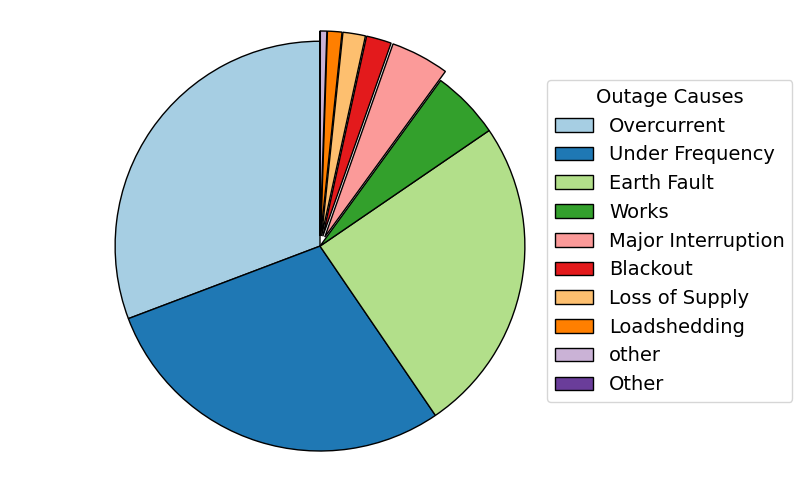

In [18]:
# Replace inconsistent cause values in the dataset
mv_outages_2017.Cause = mv_outages_2017.Cause.replace({
    'undervoltage': 'Undervoltage',
    'Planned works': 'Works',
    'Planned Works': 'Works',
    'Emergency Works': 'Works',
    'Overload': 'Loadshedding',
    'Switching Operation': 'Other',
    'Overvoltage': 'Other',
    'Undervoltage': 'Other',
    'Unidentified causes': 'Other'
})

# Count occurrences of each cause
causes = mv_outages_2017.Cause.value_counts()

# Configure font size for the plot
mpl.rcParams['font.size'] = 14

# Create the pie chart
fig, ax = plt.subplots(figsize=(8, 6))

# Set explode values to separate smaller slices (adjusted manually for demonstration)
explode = [0.05 if val < 0.05 else 0 for val in (causes / causes.sum())]

# Plot the pie chart with no annotations (no labels or percentages)
ax.pie(causes, startangle=90, 
       colors=plt.cm.Paired.colors, wedgeprops={'edgecolor': 'black'}, explode=explode)

# Adjust the legend position
plt.legend(causes.index, loc='center left', bbox_to_anchor=(0.85, 0.5), title="Outage Causes")

# Set an equal aspect ratio to ensure the pie is circular
ax.axis('equal')

# Display the plot
plt.show()